# 🟢 TP3 | Dados para Machine Learning: Feature Engineering

## ⤵️ Imports

In [ ]:
!pip install mglearn

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import FeatureHasher
from mglearn.tools import visualize_coefficients
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score
from nltk.corpus import stopwords
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import spacy
import nltk

## Parte 1 | Análise de Sentimentos com TF-IDF e Regressão Logística

#### 📍 **Questão 1:** Baixe e carregue o dataset `alexa.tsv`, com as amostras de avaliações feitas por clientes da Amazon sobre produtos adquiridos da linha Alexa, tais como Echo, Dot, Alexa, Fire, etc. O arquivo está disponível na biblioteca Python `kagglehub`, sob o dataset `sid321axn/amazon-alexa-reviews`. O arquivo contém cerca de 3000 registros de avaliações, com as seguintes informações:
* rating
* date
* variation
* verified_reviews
* feedback

Realize a vetorização e redimensionamento da feature textual (`verified_reviews`) utilizando a técnica `TF-IDF`.

In [ ]:
data = pd.read_csv("/content/drive/MyDrive/2026/2026 01/2 - Dados para Machine Learning: Feature Engineering/TP3/amazon_alexa.tsv", sep='\t')
data.head()

,rating,date,variation,verified_reviews,feedback
0,5,31-Jul-18,Charcoal Fabric,Love my Echo!,1
1,5,31-Jul-18,Charcoal Fabric,Loved it!,1
2,4,31-Jul-18,Walnut Finish,"Sometimes while playing a game, you can answer...",1
3,5,31-Jul-18,Charcoal Fabric,I have had a lot of fun with this thing. My 4 ...,1
4,5,31-Jul-18,Charcoal Fabric,Music,1


In [ ]:
data.shape

(3150, 5)

In [ ]:
data['verified_reviews'] = data['verified_reviews'].fillna('').astype(str).str.lower()

tfidf_vectorizer = TfidfVectorizer(
  max_df = 0.99,
  min_df=0.01,
  stop_words='english'
)

tfidf_matrix = tfidf_vectorizer.fit_transform(data['verified_reviews'])
tfidf_feature_names = tfidf_vectorizer.get_feature_names_out()

In [ ]:
print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("First 5 feature names:", tfidf_feature_names[:5])

TF-IDF matrix shape: (3150, 191)
First 5 feature names: ['2nd' '34' 'able' 'absolutely' 'add']


***

#### 📍 **Questão 02:** A partir do resultado da Questão 1, exiba as 40 features com os maiores valores de `TF-IDF` e as 40 com os menores valores de `TF-IDF`. Comente o que essas features nos informam (se informam algo relevante) em relação ao objetivo de **analisar sentimentos** nas avaliações dos produtos.

In [ ]:
print("\nTop features (highest IDF):")
tfidfs = tfidf_vectorizer.idf_
top_idf_idx = np.argsort(tfidfs)[::-1][:50]
for i in top_idf_idx:
    print(f"{tfidf_feature_names[i]:<18}  idf = {tfidfs[i]:.7f}")


Top features (highest IDF):
wake                idf = 5.5589676
excellent           idf = 5.5589676
buying              idf = 5.5589676
apps                idf = 5.5589676
addition            idf = 5.5589676
daughter            idf = 5.5589676
needs               idf = 5.5589676
deal                idf = 5.5589676
plays               idf = 5.5291146
wife                idf = 5.5291146
wonderful           idf = 5.5291146
came                idf = 5.5291146
instructions        idf = 5.5291146
unit                idf = 5.5001271
come                idf = 5.5001271
asking              idf = 5.5001271
command             idf = 5.5001271
living              idf = 5.5001271
look                idf = 5.5001271
looks               idf = 5.5001271
reason              idf = 5.4719562
help                idf = 5.4719562
wifi                idf = 5.4445572
night               idf = 5.4445572
long                idf = 5.4445572
fact                idf = 5.4445572
generation          idf = 5.4445572

In [ ]:
print("\nBottom features (lower IDF):")
bottom_idf_idx = np.argsort(tfidfs)[:50]
for i in bottom_idf_idx:
    print(f"{tfidf_feature_names[i]:<18}  idf = {tfidfs[i]:.7f}")


Bottom features (lower IDF):
love                idf = 2.3340494
great               idf = 2.5602096
echo                idf = 2.6652345
alexa               idf = 2.8692665
music               idf = 2.9091459
like                idf = 2.9778329
use                 idf = 3.0247899
works               idf = 3.1285491
easy                idf = 3.2871541
sound               idf = 3.3156822
just                idf = 3.3384474
set                 idf = 3.4496731
good                idf = 3.5340142
product             idf = 3.5583069
dot                 idf = 3.6261295
amazon              idf = 3.6894991
speaker             idf = 3.7179371
device              idf = 3.8514685
bought              idf = 3.8569781
home                idf = 3.8569781
time                idf = 3.8736916
play                idf = 3.8736916
really              idf = 3.8849911
better              idf = 3.9678788
smart               idf = 3.9865709
new                 idf = 4.0120500
quality             idf = 4.031594

***

#### 📍 **Questão 03:** Utilizando os dados redimensionados da **Questão 1**, construa um **modelo simples de classificação baseado em Regressão Logística**, tendo como variável-alvo ("target") o atributo `feedback` (onde `1` significa que a avaliação foi rotulada como positiva e `0` como negativa). Lembre-se de considerar o balanceamento do volume dos dados de treino em relação à variável-alvo. Divida os dados entre treino (70%) e teste (30%), aplique a regressão aos dados de treino e meça a acurácia contra os dados de teste. Informe a acurácia obtida.

In [ ]:
y = data['feedback'] # 1 is a positive review and 0 is negative
X = tfidf_matrix

train_f, test_f, train_t, test_t = train_test_split(
  X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
regressor = LogisticRegression()
regressor.fit(train_f, train_t)

regressor_pred = regressor.predict(test_f)
accuracy = accuracy_score(test_t, regressor_pred)
print("Accuracy:", accuracy)

Accuracy: 0.9174603174603174


***

#### 📍 **Questão 04:** Crie um gráfico de barras exibindo:

* Os **40 maiores coeficientes** da regressão logística construída na **Questão 3**
* Os **40 menores coeficientes**

Algum desses coeficientes parece não ser um indicador claro do sentimento para o qual foi classificado pelo modelo? Comente sua observação.

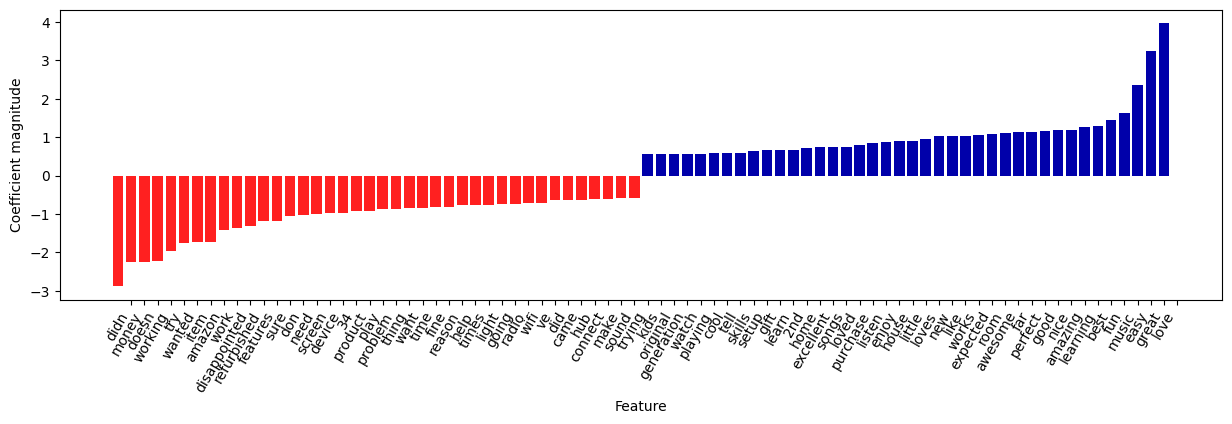

In [ ]:
visualize_coefficients(
    regressor.coef_,
    tfidf_feature_names,
    n_top_features=40)

***

## Parte 2 |  Vetorização de Variáveis Categóricas
Considere a Tabela abaixo como um toy dataset para as próximas questões.

In [ ]:
tabela = [
  ["D1", "Sol", "Quente", "Elevada", "Fraco", "Não"],
  ["D2", "Sol", "Quente", "Elevada", "Forte", "Não"],
  ["D3", "Nuvens", "Quente", "Elevada", "Fraco", "Sim"],
  ["D4", "Chuva", "Ameno", "Elevada", "Fraco", "Sim"],
  ["D5", "Chuva", "Fresco", "Normal", "Fraco", "Sim"],
  ["D6", "Chuva", "Fresco", "Normal", "Forte", "Não"],
  ["D7", "Nuvens", "Fresco", "Normal", "Fraco", "Sim"],
  ["D8", "Sol", "Ameno", "Elevada", "Fraco", "Não"],
  ["D9", "Sol", "Fresco", "Normal", "Fraco", "Sim"],
  ["D10", "Chuva", "Ameno", "Normal", "Forte", "Sim"],
  ["D11", "Sol", "Ameno", "Normal", "Forte", "Sim"],
  ["D12", "Nuvens", "Ameno", "Elevada", "Forte", "Sim"],
  ["D13", "Nuvens", "Quente", "Normal", "Fraco", "Sim"],
  ["D14", "Chuva", "Ameno", "Elevada", "Forte", "Não"],
]

# Target = Jogar tenis?
colunas = [
    'Dia','Aspecto','Temperatura','Humidade','Vento','Target'
]

In [ ]:
tabela = pd.DataFrame(tabela, columns=colunas)

#### 📍 **Questão 05:** Vetorize as variáveis categóricas da **Tabela 1** utilizando a técnica de `One-Hot Encoding`.

In [ ]:
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
categorical_cols = ['Aspecto', 'Temperatura', 'Humidade', 'Vento', 'Target']

features_ohe = encoder.fit_transform(tabela[categorical_cols])

names_ohe = encoder.get_feature_names_out(categorical_cols)
tabela_ohe = pd.DataFrame(features_ohe, columns=names_ohe)

tabela_ohe.head()

,Aspecto_Chuva,Aspecto_Nuvens,Aspecto_Sol,Temperatura_Ameno,Temperatura_Fresco,Temperatura_Quente,Humidade_Elevada,Humidade_Normal,Vento_Forte,Vento_Fraco,Target_Não,Target_Sim
0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0
1,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0
2,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0
3,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
4,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0


***

#### 📍 **Questão 06:** Vetorize as variáveis categóricas da **Tabela 1** utilizando a técnica de `Dummy Encoding`.

In [ ]:
tabela_dummies = pd.get_dummies(tabela[categorical_cols], columns=categorical_cols, drop_first=True)
tabela_dummies.head()

,Aspecto_Nuvens,Aspecto_Sol,Temperatura_Fresco,Temperatura_Quente,Humidade_Normal,Vento_Fraco,Target_Sim
0,False,True,False,True,False,True,False
1,False,True,False,True,False,False,False
2,True,False,False,True,False,True,True
3,False,False,False,False,False,True,True
4,False,False,True,False,True,True,True


***

#### 📍 **Questão 07:** Vetorize as variáveis categóricas da **Tabela 1** utilizando a técnica de `Effect Encoding`.

In [ ]:
categorical_cols = ['Aspecto', 'Temperatura', 'Humidade', 'Vento', 'Target']
tabela_effect = tabela[categorical_cols].copy()

for col in categorical_cols:
    unique_categories = tabela[col].unique()
    reference_category = unique_categories[0]

    for i, category in enumerate(unique_categories):
        if category == reference_category:
            continue

        new_col_name = f'{col}_{category}'
        tabela_effect[new_col_name] = 0
        tabela_effect.loc[tabela_effect[col] == category, new_col_name] = 1
        tabela_effect.loc[tabela_effect[col] == reference_category, new_col_name] = -1

    tabela_effect = tabela_effect.drop(columns=[col])


tabela_effect.head()

,Aspecto_Nuvens,Aspecto_Chuva,Temperatura_Ameno,Temperatura_Fresco,Humidade_Normal,Vento_Forte,Target_Sim
0,-1,-1,-1,-1,-1,-1,-1
1,-1,-1,-1,-1,-1,1,-1
2,1,0,-1,-1,-1,-1,1
3,0,1,1,0,-1,-1,1
4,0,1,0,1,1,-1,1


***

#### 📍 **Questão 08:** Compare os resultados obtidos nas **questões 5, 6 e 7**. Organize a comparação em uma **tabela** e comente as principais diferenças entre os métodos.

**Valores usando One Hot Encoder**

| Aspecto | É o valor | Não é o valor |
|---------|-----------|---------------|
| Chuva | 1 | 0 |

1 = true | 0 = false

**Valores usando Dummy Encoder**

| Aspecto | É o valor | Não é o valor |
|---------|-----------|---------------|
| Nuvem | true | false |


**Valores usando Effect Encoding**

| Aspecto | É o valor | Não é o valor |
|---------|-----------|---------------|
| Chuva | 1 | -1 |

<br>

**Diferenças**
* No `One Hot Encoder` os valores se alternam entre 1 e 0 (1 quando true e 0 quando false), trazendo uma clareza maior, mas criando uma dimensão para cada valor da categoria.
* Com o `Dummy Encoder` os valores também são claros, ou true ou false. Também cria uma dimensão para cada valor da categoria, porém remove um, pois entende-se que se nenhuma categoria está como true, seria a ultima (ou a primeira) que foi excluída.
* Já para o `Effect Encoding`, tem-se uma máxima de que os valores de cada coluna, somados, devem resultar em zero. Por isso, os mesmo se alternam entre 1, 0 e -1. Aqui também tem-se a prática de remover um valor da categoria.

***

#### 📍 **Questão 09:** Com base nos resultados das **questões 5, 6 e 7**, explique quais são as **vantagens** da vetorização de variáveis categóricas.

A vetorização de variáveis categóricas transforma categorias em valores numéricos, permitindo que algoritmos de Machine Learning consigam processar essas informações.

Além disso, técnicas como One-Hot Encoding, Dummy Encoding e Effect Encoding evitam que o modelo interprete categorias como se houvesse uma ordem ou magnitude entre elas (o que poderia ocorrer se as categorias fossem representadas apenas por números inteiros) e também preservam a informação das categorias, permitindo que o modelo identifique padrões e relações entre diferentes grupos dentro dos dados.

***

#### 📍 **Questão 10:** Agora, explique quais seriam as possíveis **desvantagens** da vetorização de variáveis categóricas, considerando os mesmos resultados.

Uma desvantagem é o aumento da dimensionalidade do dataset, principalmente quando a variável possui muitas categorias. Em métodos como One-Hot Encoding, cada categoria gera uma nova dimensão no dataset, o que pode tornar o conjunto de dados mais pesado e aumentar o custo computacional.

Outra limitação é que essas técnicas não capturam relações semânticas entre categorias. Cada categoria é tratada de forma independente, mesmo que algumas possam ter significados ou contextos semelhantes.

Além disso, em alguns modelos, a criação de múltiplas colunas derivadas da mesma variável pode gerar multicolinearidade, especialmente no caso do One-Hot Encoding completo. O que não acontece quando aplicado o Dummy Encoding ou Effect Encoding.

***

## Parte 3 | Outras Técnicas de Transformação de Features

#### 📍 **Questão 11:** Explique o que é e demonstre como pode ser utilizada a técnica de `Feature Hashing`. Para a demonstração, utilize os dados do **toy dataset** representado pela **Tabela 1**.

In [ ]:
tab = tabela.drop('Dia', axis=1)

In [ ]:
print("Dataset shape:", tab.shape)
print("\nCardinalities:")
for col in tab.columns[:-1]:
    print(f"  {col:15} → {tab[col].nunique():,} categorias")

Dataset shape: (14, 5)

Cardinalities:
  Aspecto         → 3 categorias
  Temperatura     → 3 categorias
  Humidade        → 2 categorias
  Vento           → 2 categorias


In [ ]:
def row_to_features(row):
    feats = {}
    feats[f"Aspecto_{row['Aspecto']}"]   = 1
    feats[f"Temperatura_{row['Temperatura']}"] = 1
    feats[f"Humidade_{row['Humidade']}"]   = 1
    feats[f"Vento_{row['Vento']}"] = 1
    return feats

feature_dicts = [row_to_features(row) for _, row in tab.iterrows()]
len(feature_dicts)

14

In [ ]:
n_hash_features = 2 ** 6

hasher = FeatureHasher(
    n_features=n_hash_features,
    input_type='dict',
)

X_hashed = hasher.transform(feature_dicts)

print("\nHashed matrix shape:", X_hashed.shape)

X_hashed


Hashed matrix shape: (14, 64)


<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 56 stored elements and shape (14, 64)>

In [ ]:
X = X_hashed
y = tab['Target'].values

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
  )

model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)

proba = model.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, proba)

print(f"\nLogistic Regression AUC on hashed features: {auc:.4f}")


Logistic Regression AUC on hashed features: 0.5000


`Feature Hashing` consiste em aplicar uma função hash às categorias para mapeá-las diretamente em um número fixo de colunas (dimensões). Dessa forma, diferentes categorias são convertidas em índices dentro de um vetor de tamanho pré-definido.

A principal vantagem é reduzir a dimensionalidade e o uso de memória, sendo muito útil em problemas com alto número de categorias ou textos. A desvantagem é que podem ocorrer colisões de hash, quando categorias diferentes acabam sendo representadas pela mesma posição no vetor.

***

#### 📍 **Questão 12:** Explique o que é e demonstre como pode ser utilizada a técnica de `Bin Counting`. Para a demonstração, utilize os dados do toy dataset representado pela **Tabela 1**.

In [ ]:
categories = ['Aspecto', 'Temperatura', 'Humidade', 'Vento']

for col in categories:
    bin_counts = tab[col].value_counts()
    tab[col] = tab[col].map(bin_counts)

display(tab.head())

,Aspecto,Temperatura,Humidade,Vento,Target
0,5,4,7,8,Não
1,5,4,7,6,Não
2,4,4,7,8,Sim
3,5,6,7,8,Sim
4,5,4,7,8,Sim


In [ ]:
X = tab.drop('Target', axis=1)
y = tab['Target'].values

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
  )

In [ ]:
model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42, solver='liblinear')
model.fit(X_train, y_train)

proba = model.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, proba)
print(f"Logistic Regression AUC on bin-counted features: {auc:.4f}")

predictions = model.predict(X_test)
accuracy = accuracy_score(y_test, predictions)
print(f"Logistic Regression Accuracy on bin-counted features: {accuracy:.4f}")

Logistic Regression AUC on bin-counted features: 0.0000
Logistic Regression Accuracy on bin-counted features: 0.6667


`Bin Counting` consiste em substituir cada categoria pelo número de vezes que ela aparece no conjunto de dados. Assim, categorias mais frequentes recebem valores maiores, enquanto categorias raras recebem valores menores.

Essa abordagem é simples e mantém o dataset compacto, porém pode introduzir viés relacionado à frequência das categorias, o que nem sempre reflete sua real importância para o modelo.

***